<a href="https://colab.research.google.com/github/AhmadAtwi10/generative-models-mnist/blob/main/notebooks/vae_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Training a VAE on MNIST
Enabling and testing the GPU

First, you'll need to enable GPUs for the notebook:

    Navigate to Edit→Notebook Settings
    select GPU from the Hardware Accelerator drop-down
    
You can check if the GPU works with nvidia-smi.


## Data loading
Let's import some libraries and load the MNIST dataset.

In [1]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image
import matplotlib.pyplot as plt
import IPython.display
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

bs = 100
# MNIST Dataset
train_dataset = datasets.MNIST(root='./mnist_data/', train=True, transform=transforms.ToTensor(), download=True)
test_dataset = datasets.MNIST(root='./mnist_data/', train=False, transform=transforms.ToTensor(), download=False)

# Data Loader (Input Pipeline)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

## Architecture specification

You can use the following encoder (don't forget that in a VAE the decoder has two heads, for the mean and the variance):
```
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc31): Linear(in_features=256, out_features=2, bias=True)
  (fc32): Linear(in_features=256, out_features=2, bias=True)
```
and this decoder:
```
  (fc4): Linear(in_features=2, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=512, bias=True)
  (fc6): Linear(in_features=512, out_features=784, bias=True)
```
Then, you need to complete the forward function. You can use Relu activations for every layers except for the heads that can reach negative values. Concerning the decoder head, you can use sigmoid to obtain values in [0,1].

Here we consider a latent space of dimension 2 but is could be any *zdim* dimension.

In [2]:
class VAE(nn.Module):
    def __init__(self, x_dim, h_dim1, h_dim2, z_dim):
        super(VAE, self).__init__()

        # encoder part
        self.fc1 = nn.Linear(x_dim,h_dim1)
        self.fc2 = nn.Linear(h_dim1,h_dim2)
        self.fc31 = nn.Linear(h_dim2,z_dim)
        self.fc32 = nn.Linear(h_dim2,z_dim)

        # decoder part
        self.fc4 = nn.Linear(z_dim,h_dim2)
        self.fc5 = nn.Linear(h_dim2,h_dim1)
        self.fc6 = nn.Linear(h_dim1,x_dim)


    def encoder(self, x):
        h = F.relu(self.fc1(x.view(-1,784)))
        h = F.relu(self.fc2(h))

        return  self.fc31(h), self.fc32(h)

    def sampling(self, mu, log_var):
        std = torch.exp(0.5*log_var)
        eps = torch.randn_like(std) # std is used only for its dimensions
        return mu + eps*std

    def decoder(self, z):
        h = F.relu(self.fc4(z))
        h = F.relu(self.fc5(h))
        return torch.sigmoid(self.fc6(h))


    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.sampling(mu, log_var)
        image_rec = self.decoder(z)
        return image_rec, mu, log_var


## Loss function
The total loss of the VAE is composed of two terms: a reconstruction term and the KL divergence with the Prior. The KL divergence between two gaussians is given by:

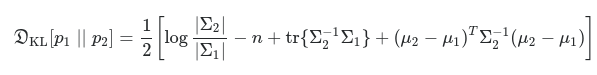

Assuming a unit gaussian as prior, we obtain a very simple equation that will help you to implement it in pytorch:

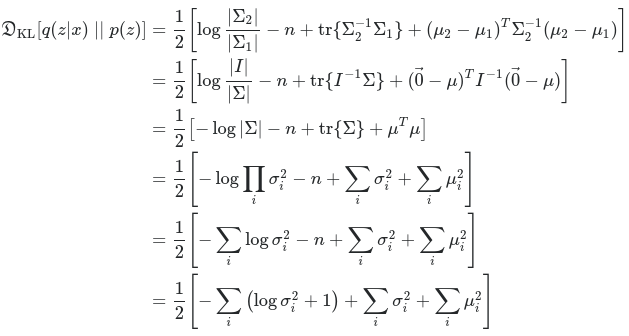

Note that, in these equations sigma denotes the standard deviation (square root of the variance) while the encoder network ouputs the log of the variance.  

In [3]:
vae = VAE(x_dim=784, h_dim1= 512, h_dim2=256, z_dim=2)
vae.to(device)
optimizer = optim.Adam(vae.parameters())

# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var):
    RecLoss = F.mse_loss(recon_x,x.view(-1,784),reduction='sum')
    KLDLoss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return RecLoss + KLDLoss

## Training step
In this cell, we define the function that performs training on one epoch. We recommend to debug it using the "main loop" cell later in the page.

In [4]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()

        recon,mu,log_var = vae(data)

        # ...
        loss = loss_function(recon, data, mu, log_var)

        loss.backward()
        train_loss += loss.item()
        optimizer.step()

        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

## Visualization:
We provide some visualization functions:

In [5]:
# Create a wall of generated MNIST images
def plotGeneratedImages(generatedImages,dim=(10, 10), figsize=(10, 10)):
    generatedImages=generatedImages.cpu().numpy()
    print(generatedImages.shape)
    plt.figure(figsize=figsize)
    for i in range(generatedImages.shape[0]):
        plt.subplot(dim[0], dim[1], i+1)
        plt.imshow(np.squeeze(generatedImages[i]), interpolation='nearest', cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## Test
Complete the test function that generate new sample from latent space samples.

In [6]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.to(device)
            recon, mu, log_var = vae(data)

            loss = loss_function(recon, data, mu, log_var)

            # sum up batch loss
            test_loss += loss.item()

    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))
    with torch.no_grad():
      z = torch.randn(64, 2).to(device)
      generated = vae.decoder(z)
      plotGeneratedImages(generated.view(generated.size(0), 1, 28, 28))
      #save_image(sample.view(64, 1, 28, 28), '.sample_' + '.png')

## Main loop

Train Epoch: 1 [0/60000 (0%)]	Loss: 182.749023


Train Epoch: 1 [10000/60000 (17%)]	Loss: 52.594326


Train Epoch: 1 [20000/60000 (33%)]	Loss: 48.677891


Train Epoch: 1 [30000/60000 (50%)]	Loss: 45.500737


Train Epoch: 1 [40000/60000 (67%)]	Loss: 41.948228


Train Epoch: 1 [50000/60000 (83%)]	Loss: 41.509448


... (16 outputs left out)

Train Epoch: 4 [40000/60000 (67%)]	Loss: 36.671448


Train Epoch: 4 [50000/60000 (83%)]	Loss: 36.061443


====> Epoch: 4 Average loss: 37.4891


====> Test set loss: 37.1026
(64, 1, 28, 28)


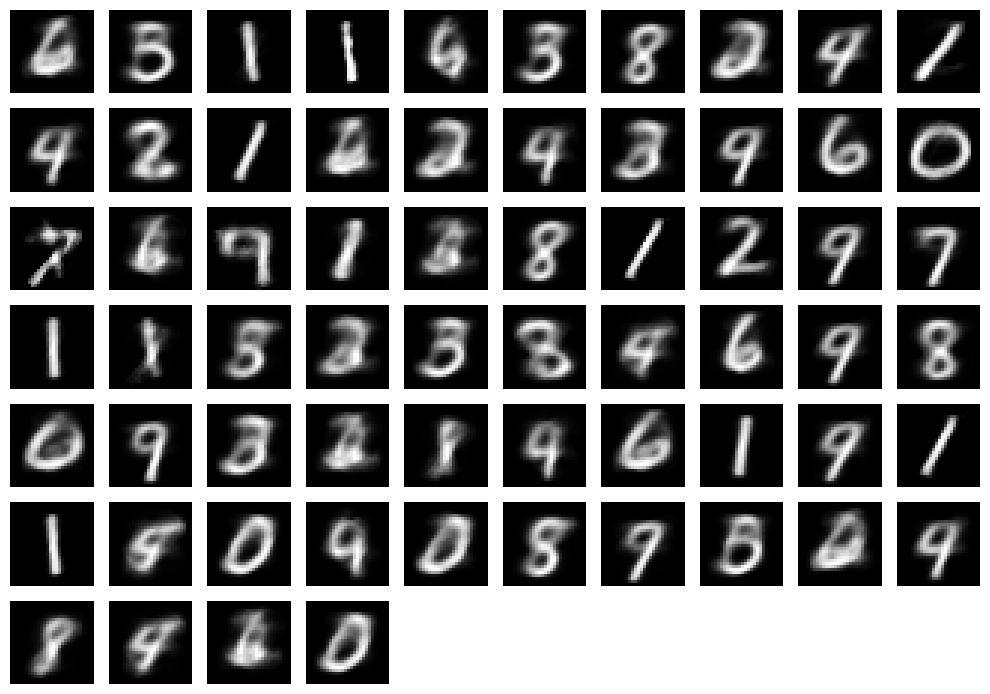

In [7]:

for epoch in range(1, 5):
    train(epoch)
test()


## Bonus 1: Interpolation
Sample two latent vectors z1 and z2 and generate the corresponding images. Then, generate 10 intermediate images by performing linear interpolation in the latent space between the z1 and z2.

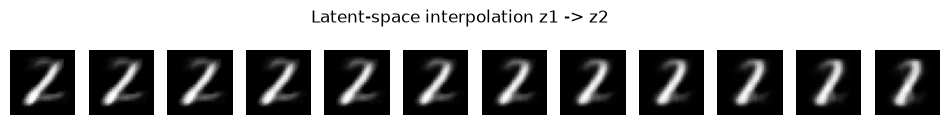

In [8]:
# Linear interpolation between two random latent codes
vae.eval()
with torch.no_grad():
    z1, z2 = torch.randn(1, 2, device=device), torch.randn(1, 2, device=device)
    alphas = torch.linspace(0, 1, 12, device=device).unsqueeze(1)
    z = (1 - alphas) * z1 + alphas * z2
    imgs = vae.decoder(z).view(-1, 28, 28).cpu().numpy()

plt.figure(figsize=(12, 1.5))
for i, img in enumerate(imgs):
    plt.subplot(1, len(imgs), i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle('Latent-space interpolation z1 -> z2')
plt.show()

## Bonus 2: Visualization
Generate a 10x10 mosaic by sampling *z* over a regulargrid in [-1,1]x[-1,1]. What do you observe?


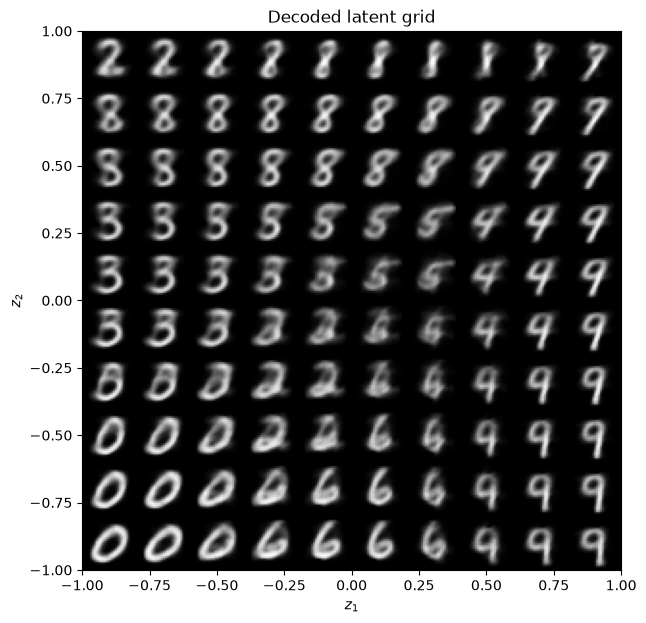

In [9]:
# 10x10 mosaic decoded from a regular grid over the 2-D latent space [-1, 1] x [-1, 1]
n = 10
grid = torch.linspace(-1, 1, n)
with torch.no_grad():
    z = torch.stack([torch.tensor([x, y]) for y in grid.flip(0) for x in grid]).to(device)
    imgs = vae.decoder(z).view(n, n, 28, 28).cpu().numpy()

mosaic = imgs.transpose(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(7, 7))
plt.imshow(mosaic, cmap='gray', extent=[-1, 1, -1, 1])
plt.xlabel('$z_1$'); plt.ylabel('$z_2$')
plt.title('Decoded latent grid')
plt.show()

**Observation:** with a 2-D latent space the decoder organises digits into smooth regions; neighbouring grid points decode to similar shapes and digit classes morph continuously into one another.